# Cross-Hospital Variation in Lab Measurement Features

This exploratory analysis uses the eICU demo dataset to examine whether
measurement-related features differ across hospitals.

I look at three related questions:

1. Does overall lab measurement frequency vary across hospitals?
2. Are some common labs recorded more consistently across hospitals than others?
3. Do the observed value distributions of common labs also shift across hospitals?

The goal is to explore possible sources of feature instability relevant to
cross-hospital generalization.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Change this path if the eICU demo data are stored elsewhere.
data_dir = (
    Path.home()
    / 'Documents'
    / 'data'
    / 'eicu-collaborative-research-database-demo-2.0.1'
)

In [2]:
patient = pd.read_csv(data_dir / 'patient.csv.gz')
lab = pd.read_csv(data_dir / 'lab.csv.gz')

print("Patient table:", patient.shape)
print("Lab table:", lab.shape)

Patient table: (2520, 29)
Lab table: (434660, 10)


In [3]:
stay_info = patient[
    ['patientunitstayid',
     'patienthealthsystemstayid',
     'hospitalid',
     'hospitaladmitoffset']
].copy()

lab = lab.merge(stay_info, on='patientunitstayid', how='inner')

print(lab.shape)
lab[['patientunitstayid', 'patienthealthsystemstayid',
     'hospitalid', 'labname', 'labresultoffset',
     'hospitaladmitoffset']].head()

(434660, 13)


,patientunitstayid,patienthealthsystemstayid,hospitalid,labname,labresultoffset,hospitaladmitoffset
0,1754323,1374785,277,Hct,-647,-695
1,1754323,1374785,277,platelets x 1000,-647,-695
2,1754323,1374785,277,RBC,-647,-695
3,1754323,1374785,277,-monos,-647,-695
4,1754323,1374785,277,MCHC,-647,-695


## 1. Overall lab measurement frequency across hospitals

I first compare how frequently labs are measured across hospitals during the
first 48 hours of a hospitalization. Several lab results can come from the same
blood draw, so measurements at the same timestamp are treated as one lab event.

In [4]:
# Convert lab timing to hours since hospital admission.
lab['hours'] = (
    -lab['hospitaladmitoffset'] + lab['labresultoffset']
) / 60

# Restrict to measurements from the first 48 hours.
lab_48h = lab[
    (lab['hours'] >= 0) &
    (lab['hours'] < 48)
].copy()

# Keep this general lab-frequency analysis separate from the
# kidney-specific creatinine analysis.
lab_48h = lab_48h[
    lab_48h['labname'].str.lower() != 'creatinine'
]

# Several lab results can come from one blood draw, so count
# each hospitalization/timestamp combination as one lab event.
lab_events = lab_48h[
    ['patienthealthsystemstayid', 'hospitalid', 'hours']
].drop_duplicates()

print("Lab events:", len(lab_events))
print(
    "Hospitalizations:",
    lab_events['patienthealthsystemstayid'].nunique()
)
print("Hospitals:", lab_events['hospitalid'].nunique())

Lab events: 21825
Hospitalizations: 2110
Hospitals: 186


In [5]:
# One row per hospitalization.
all_stays = (
    patient[['patienthealthsystemstayid', 'hospitalid']]
    .drop_duplicates('patienthealthsystemstayid')
)

# Number of distinct lab events per hospitalization.
lab_counts = (
    lab_events
    .groupby('patienthealthsystemstayid')
    .size()
    .reset_index(name='lab_events_48h')
)

# Hospitalizations without a qualifying lab event receive a count of zero.
patient_lab_counts = all_stays.merge(
    lab_counts,
    on='patienthealthsystemstayid',
    how='left'
)

patient_lab_counts['lab_events_48h'] = (
    patient_lab_counts['lab_events_48h'].fillna(0)
)

hospital_summary = (
    patient_lab_counts
    .groupby('hospitalid')['lab_events_48h']
    .agg(['count', 'mean', 'median'])
    .reset_index()
)

# Use hospitals represented by at least 10 hospitalizations.
hospital_summary = (
    hospital_summary[hospital_summary['count'] >= 10]
    .sort_values('median', ascending=False)
)

print(
    "Hospitals with at least 10 stays:",
    len(hospital_summary)
)

Hospitals with at least 10 stays: 186


In [6]:
print(hospital_summary[['mean', 'median']].describe().round(2))

print("\nHighest median lab frequency:")
display(hospital_summary.head(5))

print("\nLowest median lab frequency:")
display(hospital_summary.tail(5))

         mean  median
count  186.00  186.00
mean    10.00    8.01
std      4.35    3.86
min      1.23    1.00
25%      6.56    5.00
50%      9.35    7.00
75%     13.06   11.00
max     22.54   19.00

Highest median lab frequency:


,hospitalid,count,mean,median
13,83,11,20.818182,19.0
134,382,14,19.785714,19.0
32,144,13,22.538462,19.0
33,146,26,15.769231,17.0
76,227,11,15.181818,16.0



Lowest median lab frequency:


,hospitalid,count,mean,median
166,423,11,3.545455,2.0
27,138,13,1.230769,1.0
26,133,14,1.428571,1.0
23,123,21,1.428571,1.0
21,120,10,1.300000,1.0


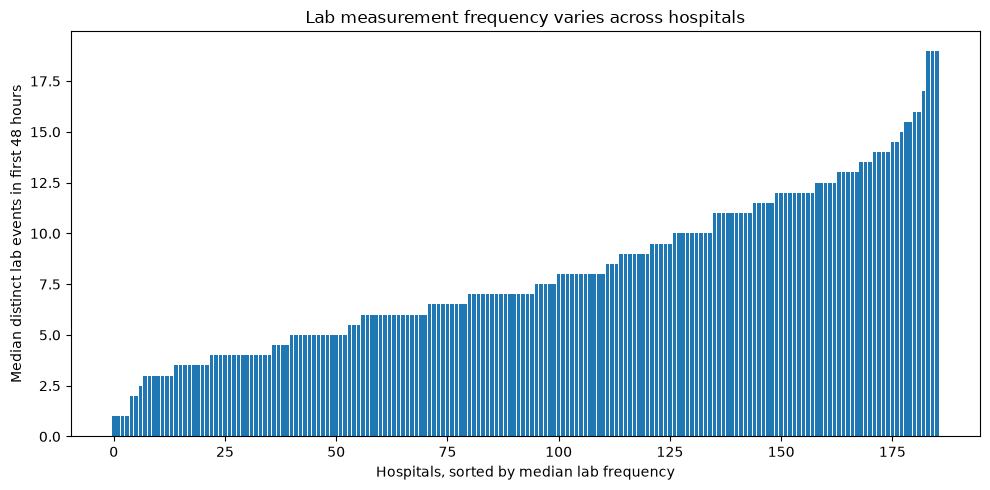

In [7]:
plot_data = hospital_summary.sort_values('median')

plt.figure(figsize=(10, 5))
plt.bar(range(len(plot_data)), plot_data['median'])

plt.xlabel('Hospitals, sorted by median lab frequency')
plt.ylabel('Median distinct lab events in first 48 hours')
plt.title('Lab measurement frequency varies across hospitals')

plt.tight_layout()
plt.savefig(
    'liam_lab_frequency_across_hospitals.png',
    dpi=200,
    bbox_inches='tight'
)
plt.show()

## 2. Cross-hospital feature availability

Next, I look at the 15 most common lab features and measure the fraction of
hospitalizations at each hospital in which each lab was recorded at least once.

Differences in this rate provide one simple measure of how site-dependent a
feature's availability is.

In [8]:
common_labs = (
    lab_48h['labname']
    .value_counts()
    .head(15)
)

display(common_labs)

labname
bedside glucose     9499
potassium           5970
sodium              5710
glucose             5432
chloride            5314
BUN                 5252
Hgb                 5127
calcium             5037
Hct                 4996
bicarbonate         4992
platelets x 1000    4319
WBC x 1000          4307
RBC                 4254
MCV                 4193
MCHC                4187
Name: count, dtype: int64

In [9]:
top_labs = common_labs.index

# Record whether each lab appeared at least once during a hospitalization.
lab_presence = (
    lab_48h[lab_48h['labname'].isin(top_labs)]
    [['patienthealthsystemstayid', 'hospitalid', 'labname']]
    .drop_duplicates()
)

# Number of hospitalizations represented at each hospital.
hospital_n = (
    patient[['patienthealthsystemstayid', 'hospitalid']]
    .drop_duplicates()
    .groupby('hospitalid')
    .size()
    .rename('n_stays')
)

# Fraction of hospitalizations at each hospital in which each lab was recorded.
presence_by_hospital = (
    lab_presence
    .groupby(['hospitalid', 'labname'])
    .size()
    .unstack(fill_value=0)
    .div(hospital_n, axis=0)
)

In [10]:
# Require at least 12 hospitalizations per hospital.
# This retains 75 hospitals in the demo dataset.
hospitals_12 = hospital_n[hospital_n >= 12].index

presence_12 = presence_by_hospital.loc[
    presence_by_hospital.index.intersection(hospitals_12)
]

availability_stability = pd.DataFrame({
    'mean_measurement_rate': presence_12.mean(),
    'availability_instability': presence_12.std(),
    'min_rate': presence_12.min(),
    'max_rate': presence_12.max()
})

availability_stability['range'] = (
    availability_stability['max_rate']
    - availability_stability['min_rate']
)

availability_stability = availability_stability.sort_values(
    'availability_instability',
    ascending=False
)

display(availability_stability.round(3))
print("Hospitals included:", len(presence_12))

,mean_measurement_rate,availability_instability,min_rate,max_rate,range
labname,,,,,
bedside glucose,0.506,0.285,0.000,1.0,1.000
bicarbonate,0.871,0.240,0.000,1.0,1.000
MCV,0.863,0.233,0.000,1.0,1.000
MCHC,0.862,0.233,0.000,1.0,1.000
calcium,0.880,0.225,0.000,1.0,1.000
RBC,0.874,0.208,0.000,1.0,1.000
platelets x 1000,0.877,0.195,0.000,1.0,1.000
Hgb,0.884,0.183,0.143,1.0,0.857
chloride,0.901,0.180,0.143,1.0,0.857


Hospitals included: 75


## 3. Cross-hospital value-distribution shift

Feature availability is only one possible source of variation. I also compare
the typical observed values of common labs across hospitals.

Because the labs use different units and scales, each feature is centered by its
overall median and scaled by its interquartile range before hospital medians are
compared. This is an exploratory measure of distribution shift rather than a
formal measure of feature stability.

In [11]:
value_data = lab_48h[
    lab_48h['labname'].isin(top_labs)
].copy()

value_data['labresult'] = pd.to_numeric(
    value_data['labresult'],
    errors='coerce'
)

value_data = value_data.dropna(subset=['labresult'])

# Use the same 75-hospital subset as the availability analysis.
value_data = value_data[
    value_data['hospitalid'].isin(hospitals_12)
]

results = []

for lab_name in top_labs:
    x = value_data[value_data['labname'] == lab_name].copy()

    # Robustly scale each lab so features with different units
    # can be compared on a common scale.
    median = x['labresult'].median()
    q1 = x['labresult'].quantile(0.25)
    q3 = x['labresult'].quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        continue

    x['scaled_result'] = (
        x['labresult'] - median
    ) / iqr

    # Collapse repeated measurements to one typical value
    # per hospitalization before comparing hospitals.
    patient_values = (
        x.groupby(
            ['hospitalid', 'patienthealthsystemstayid']
        )['scaled_result']
        .median()
        .reset_index()
    )

    hospital_counts = (
        patient_values
        .groupby('hospitalid')
        .size()
    )

    valid_hospitals = hospital_counts[
        hospital_counts >= 5
    ].index

    hospital_medians = (
        patient_values[
            patient_values['hospitalid'].isin(valid_hospitals)
        ]
        .groupby('hospitalid')['scaled_result']
        .median()
    )

    results.append({
        'labname': lab_name,
        'hospitals_used': len(hospital_medians),
        'value_distribution_shift': hospital_medians.std()
    })

value_shift = (
    pd.DataFrame(results)
    .sort_values(
        'value_distribution_shift',
        ascending=False
    )
)

display(value_shift.round(3))

,labname,hospitals_used,value_distribution_shift
3,glucose,74,0.485
2,sodium,75,0.360
9,bicarbonate,70,0.349
12,RBC,71,0.339
13,MCV,71,0.338
4,chloride,72,0.335
10,platelets x 1000,72,0.326
7,calcium,70,0.318
0,bedside glucose,54,0.305
8,Hct,75,0.302


## 4. Comparing different forms of feature variation

Finally, I compare variation in feature availability with variation in observed
feature values. These two quantities do not necessarily rank features in the
same way, which suggests that cross-hospital instability may have multiple
components.

,availability_instability,value_distribution_shift
labname,,
bedside glucose,0.285,0.305
bicarbonate,0.240,0.349
MCV,0.233,0.338
MCHC,0.233,0.264
calcium,0.225,0.318
RBC,0.208,0.339
platelets x 1000,0.195,0.326
Hgb,0.183,0.294
chloride,0.180,0.335


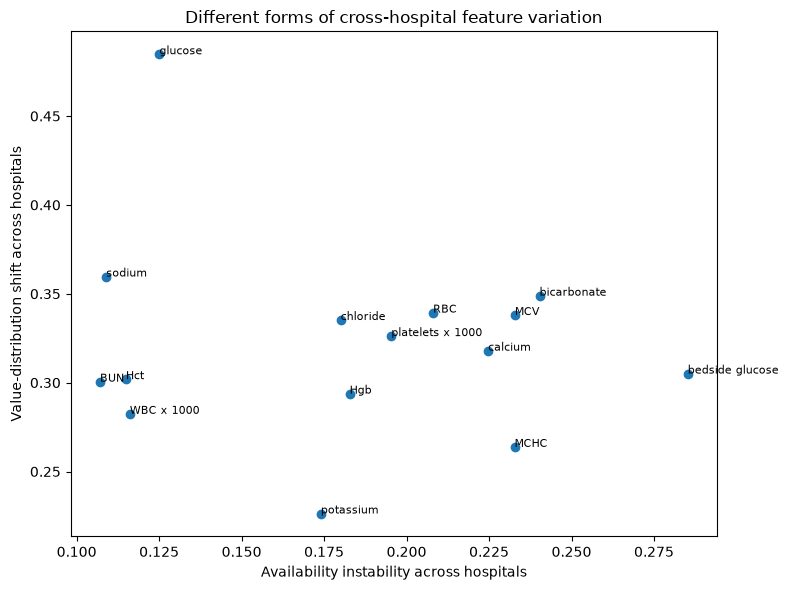

In [12]:
# Compare availability variation with numerical distribution shift.
stability_compare = (
    availability_stability[
        ['availability_instability']
    ]
    .join(
        value_shift
        .set_index('labname')[
            ['value_distribution_shift']
        ]
    )
)

display(stability_compare.round(3))

plt.figure(figsize=(8, 6))

plt.scatter(
    stability_compare['availability_instability'],
    stability_compare['value_distribution_shift']
)

for lab_name, row in stability_compare.iterrows():
    plt.annotate(
        lab_name,
        (
            row['availability_instability'],
            row['value_distribution_shift']
        ),
        fontsize=8
    )

plt.xlabel('Availability instability across hospitals')
plt.ylabel('Value-distribution shift across hospitals')
plt.title('Different forms of cross-hospital feature variation')

plt.tight_layout()
plt.savefig(
    'liam_lab_feature_instability.png',
    dpi=200,
    bbox_inches='tight'
)
plt.show()

stability_compare.round(3).to_csv(
    'liam_lab_feature_instability.csv'
)

## Takeaways

Overall lab measurement frequency varies substantially across hospitals in the
demo data. Common lab features also differ in how consistently they are recorded
across sites.

Feature availability and numerical-value variation do not produce the same
ranking of features. This suggests that a feature can be relatively stable in
one sense while still varying substantially across hospitals in another.

These results are exploratory because the demo dataset contains relatively few
patients per hospital.